# Selecting the difference order for out-of-sample stability

The augmented Dickey Fuller calculation tests whether the transformed series still behaves as if it has a unit root:

$$
\Delta Y_t=\alpha_0+\rho Y_{t-1}+\gamma\Delta Y_{t-1}+\varepsilon_t,
\qquad H_0:\rho=0.
$$

Here, $Y_t$ is the transformed value; $\Delta Y_t=Y_t-Y_{t-1}$; $\alpha_0$ is a constant; $\rho$ is the level coefficient. $\gamma$ is the coefficient on one lagged change; $\varepsilon_t$ is the remaining error; $H_0$ is the unit-root null statement.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
from scipy.signal import fftconvolve
from statsmodels.tsa.stattools import adfuller

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.differentiation import adaptive_fractional_difference, calculate_weights_ffd, calculate_weights_std, fractional_difference_fixed, fractional_difference_fixed_single, fractional_difference_std

FIGURES = ROOT / "outputs" / "figures" / "08_fractional_differentiation"
TABLES = ROOT / "outputs" / "tables" / "08_fractional_differentiation"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def natural_weights(degree, size):
    values = [1.0]
    for k in range(1, size):
        values.append(-values[-1] * (degree - k + 1) / k)
    return np.asarray(values, dtype=float)

def adf_record(values):
    result = adfuller(np.asarray(values, dtype=float), maxlag=1, regression="c", autolag=None)
    return {"ADF statistic": float(result[0]), "p-value": float(result[1]), "Used lag": int(result[2]), "Observations in test": int(result[3]), "Five percent critical value": float(result[4]["5%"]) }

raw = raw.sort_values("time").dropna(subset=["time", "close"]).drop_duplicates("time").reset_index(drop=True)
minute_close = pd.Series(raw["close"].to_numpy(dtype=float), index=pd.DatetimeIndex(raw["time"]), name="One-minute close")
close = minute_close.resample("15min").last().dropna().rename("Fifteen-minute close")
log_price = np.log(close).rename("Log price")
log_frame = log_price.rename("close").to_frame()
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Training Rule

Among the tested orders, the training rule chooses the smallest one whose unit-root p-value is below the chosen level:

$$
\widehat d=\min\{d\in\mathcal D:p_{\mathrm{train}}(d)<\alpha\},
\qquad \mathcal D=\{0,0.1,\ldots,1\},\qquad \alpha=0.05.
$$

Here, $\widehat d$ is the selected order; $\mathcal D$ is the fixed set of candidate orders; $p_{\mathrm{train}}(d)$ is the training p-value. $\alpha=0.05$ is the decision level; $\min$ selects the smallest passing candidate.

In [2]:
degrees = np.round(np.linspace(0.0, 1.0, 11), 1)
threshold = 1e-3
significance = 0.05
split_position = int(0.70 * len(log_frame))
train = log_frame.iloc[:split_position]
test_index = log_frame.index[split_position:]

def evaluate(frame, degree, cutoff):
    transformed = fractional_difference_fixed(frame, float(degree), threshold=cutoff).dropna()["close"]
    record = adf_record(transformed)
    record.update({"Order": float(degree), "Cutoff": cutoff, "Retained weights": len(calculate_weights_ffd(float(degree), cutoff)), "Usable observations": len(transformed), "Correlation with log price": float(np.corrcoef(frame.loc[transformed.index, "close"], transformed)[0, 1])})
    return record, transformed

train_rows = []
train_series = {}
for degree in degrees:
    record, transformed = evaluate(train, degree, threshold)
    train_rows.append(record)
    train_series[float(degree)] = transformed
train_order_selection = pd.DataFrame(train_rows)[["Order", "Retained weights", "Usable observations", "ADF statistic", "p-value", "Five percent critical value", "Correlation with log price"]]
passing_train = train_order_selection.loc[train_order_selection["p-value"] < significance, "Order"]
selected_degree = float(passing_train.min())

test_rows = []
full_series = {}
for degree in degrees:
    record, transformed = evaluate(log_frame, degree, threshold)
    held_out = transformed.loc[transformed.index.intersection(test_index)]
    test_record = adf_record(held_out)
    test_rows.append({"Order": float(degree), "Retained weights": record["Retained weights"], "Held-out observations": len(held_out), "ADF statistic": test_record["ADF statistic"], "p-value": test_record["p-value"], "Five percent critical value": test_record["Five percent critical value"], "Correlation with log price": np.corrcoef(log_frame.loc[held_out.index, "close"], held_out)[0, 1]})
    full_series[float(degree)] = transformed
test_order_evaluation = pd.DataFrame(test_rows)

sensitivity_rows = []
for cutoff in [1e-2, 1e-3, 1e-4, 1e-5]:
    candidate_rows = []
    for degree in degrees:
        transformed = fractional_difference_fixed(train, float(degree), threshold=cutoff).dropna()["close"]
        if len(transformed) < 20:
            continue
        candidate_rows.append({"Order": float(degree), "p-value": adf_record(transformed)["p-value"], "Retained weights": len(calculate_weights_ffd(float(degree), cutoff)), "Correlation": np.corrcoef(train.loc[transformed.index, "close"], transformed)[0, 1]})
    candidates = pd.DataFrame(candidate_rows)
    passing = candidates[candidates["p-value"] < significance]
    chosen = passing.iloc[0]
    full = fractional_difference_fixed(log_frame, float(chosen["Order"]), threshold=cutoff).dropna()["close"]
    held_out = full.loc[full.index.intersection(test_index)]
    sensitivity_rows.append({"Cutoff": cutoff, "Selected order": chosen["Order"], "Retained weights": int(chosen["Retained weights"]), "Training observations": int(len(fractional_difference_fixed(train, float(chosen["Order"]), threshold=cutoff).dropna())), "Training p-value": chosen["p-value"], "Training correlation": chosen["Correlation"], "Held-out observations": len(held_out), "Held-out p-value": adf_record(held_out)["p-value"], "Held-out correlation": np.corrcoef(log_frame.loc[held_out.index, "close"], held_out)[0, 1]})
threshold_sensitivity = pd.DataFrame(sensitivity_rows)

save_table(train_order_selection, "train_order_selection", "Training results for candidate fractional orders.", "tab:chapter7-train-selection", fit=True)
save_table(test_order_evaluation, "test_order_evaluation", "Held-out results using fixed weights and earlier history.", "tab:chapter7-test-evaluation", fit=True)
save_table(threshold_sensitivity, "threshold_sensitivity", "Sensitivity of order selection to the weight cutoff.", "tab:chapter7-threshold-sensitivity", fit=True)
display(train_order_selection.round(8))
display(test_order_evaluation.round(8))
display(threshold_sensitivity.round(8))

,Order,Retained weights,Usable observations,ADF statistic,p-value,Five percent critical value,Correlation with log price
0,0,1,2083,-2.510958,0.112831,-2.862930,1
1,0.1,62,2022,-3.455511,0.009206,-2.862972,0.994709
2,0.2,73,2011,-5.079771,0.000015,-2.862980,0.965977
3,0.3,66,2018,-7.302303,0,-2.862975,0.907210
4,0.4,55,2029,-10.320835,0,-2.862967,0.814786
5,0.5,44,2040,-14.077537,0,-2.862959,0.689854
6,0.6,34,2050,-18.280527,0,-2.862952,0.547926
7,0.7,26,2058,-22.662328,0,-2.862947,0.405447
8,0.8,18,2066,-26.847336,0,-2.862941,0.288527
9,0.9,12,2072,-30.874424,0,-2.862937,0.174918


,Order,Retained weights,Held-out observations,ADF statistic,p-value,Five percent critical value,Correlation with log price
0,0,1,893,-2.493521,1.170587e-01,-2.864789,1
1,0.1,62,893,-3.411622,1.056899e-02,-2.864789,0.986658
2,0.2,73,893,-4.693339,8.661000e-05,-2.864789,0.932941
3,0.3,66,893,-6.284649,4.000000e-08,-2.864789,0.842830
4,0.4,55,893,-8.161126,0,-2.864789,0.725315
5,0.5,44,893,-10.235398,0,-2.864789,0.593907
6,0.6,34,893,-12.405717,0,-2.864789,0.464685
7,0.7,26,893,-14.606911,0,-2.864789,0.347155
8,0.8,18,893,-16.761024,0,-2.864789,0.253563
9,0.9,12,893,-18.772160,0,-2.864789,0.171680


,Cutoff,Selected order,Retained weights,Training observations,Training p-value,Training correlation,Held-out observations,Held-out p-value,Held-out correlation
0,0.01000,0.2,11,2073,0.006101,0.995545,893,0.002125,0.985179
1,0.00100,0.1,62,2022,0.009206,0.994709,893,0.010569,0.986658
2,0.00010,0.1,503,1581,0.020725,0.981137,893,0.010836,0.980966
3,0.00001,0.4,1458,626,0,0.741655,893,0,0.705437


## Held-Out Evaluation

After the order is chosen on training data, each held-out value uses only its present and past levels with the already fixed weights:

$$
\widetilde X_t^{(\widehat d,\tau)}
=\sum_{k=0}^{m_{\tau}(\widehat d)-1}\omega_kX_{t-k},
\qquad t\in\mathcal T_{\mathrm{test}}.
$$

Here, $\widehat d$ is the training-selected order; $\tau$ is the fixed cutoff; $m_{\tau}(\widehat d)$ is the retained weight count. $\omega_k$ is the weight at lag $k$; $X_{t-k}$ is an observed present or past level; $\mathcal T_{\mathrm{test}}$ is the held-out time set.

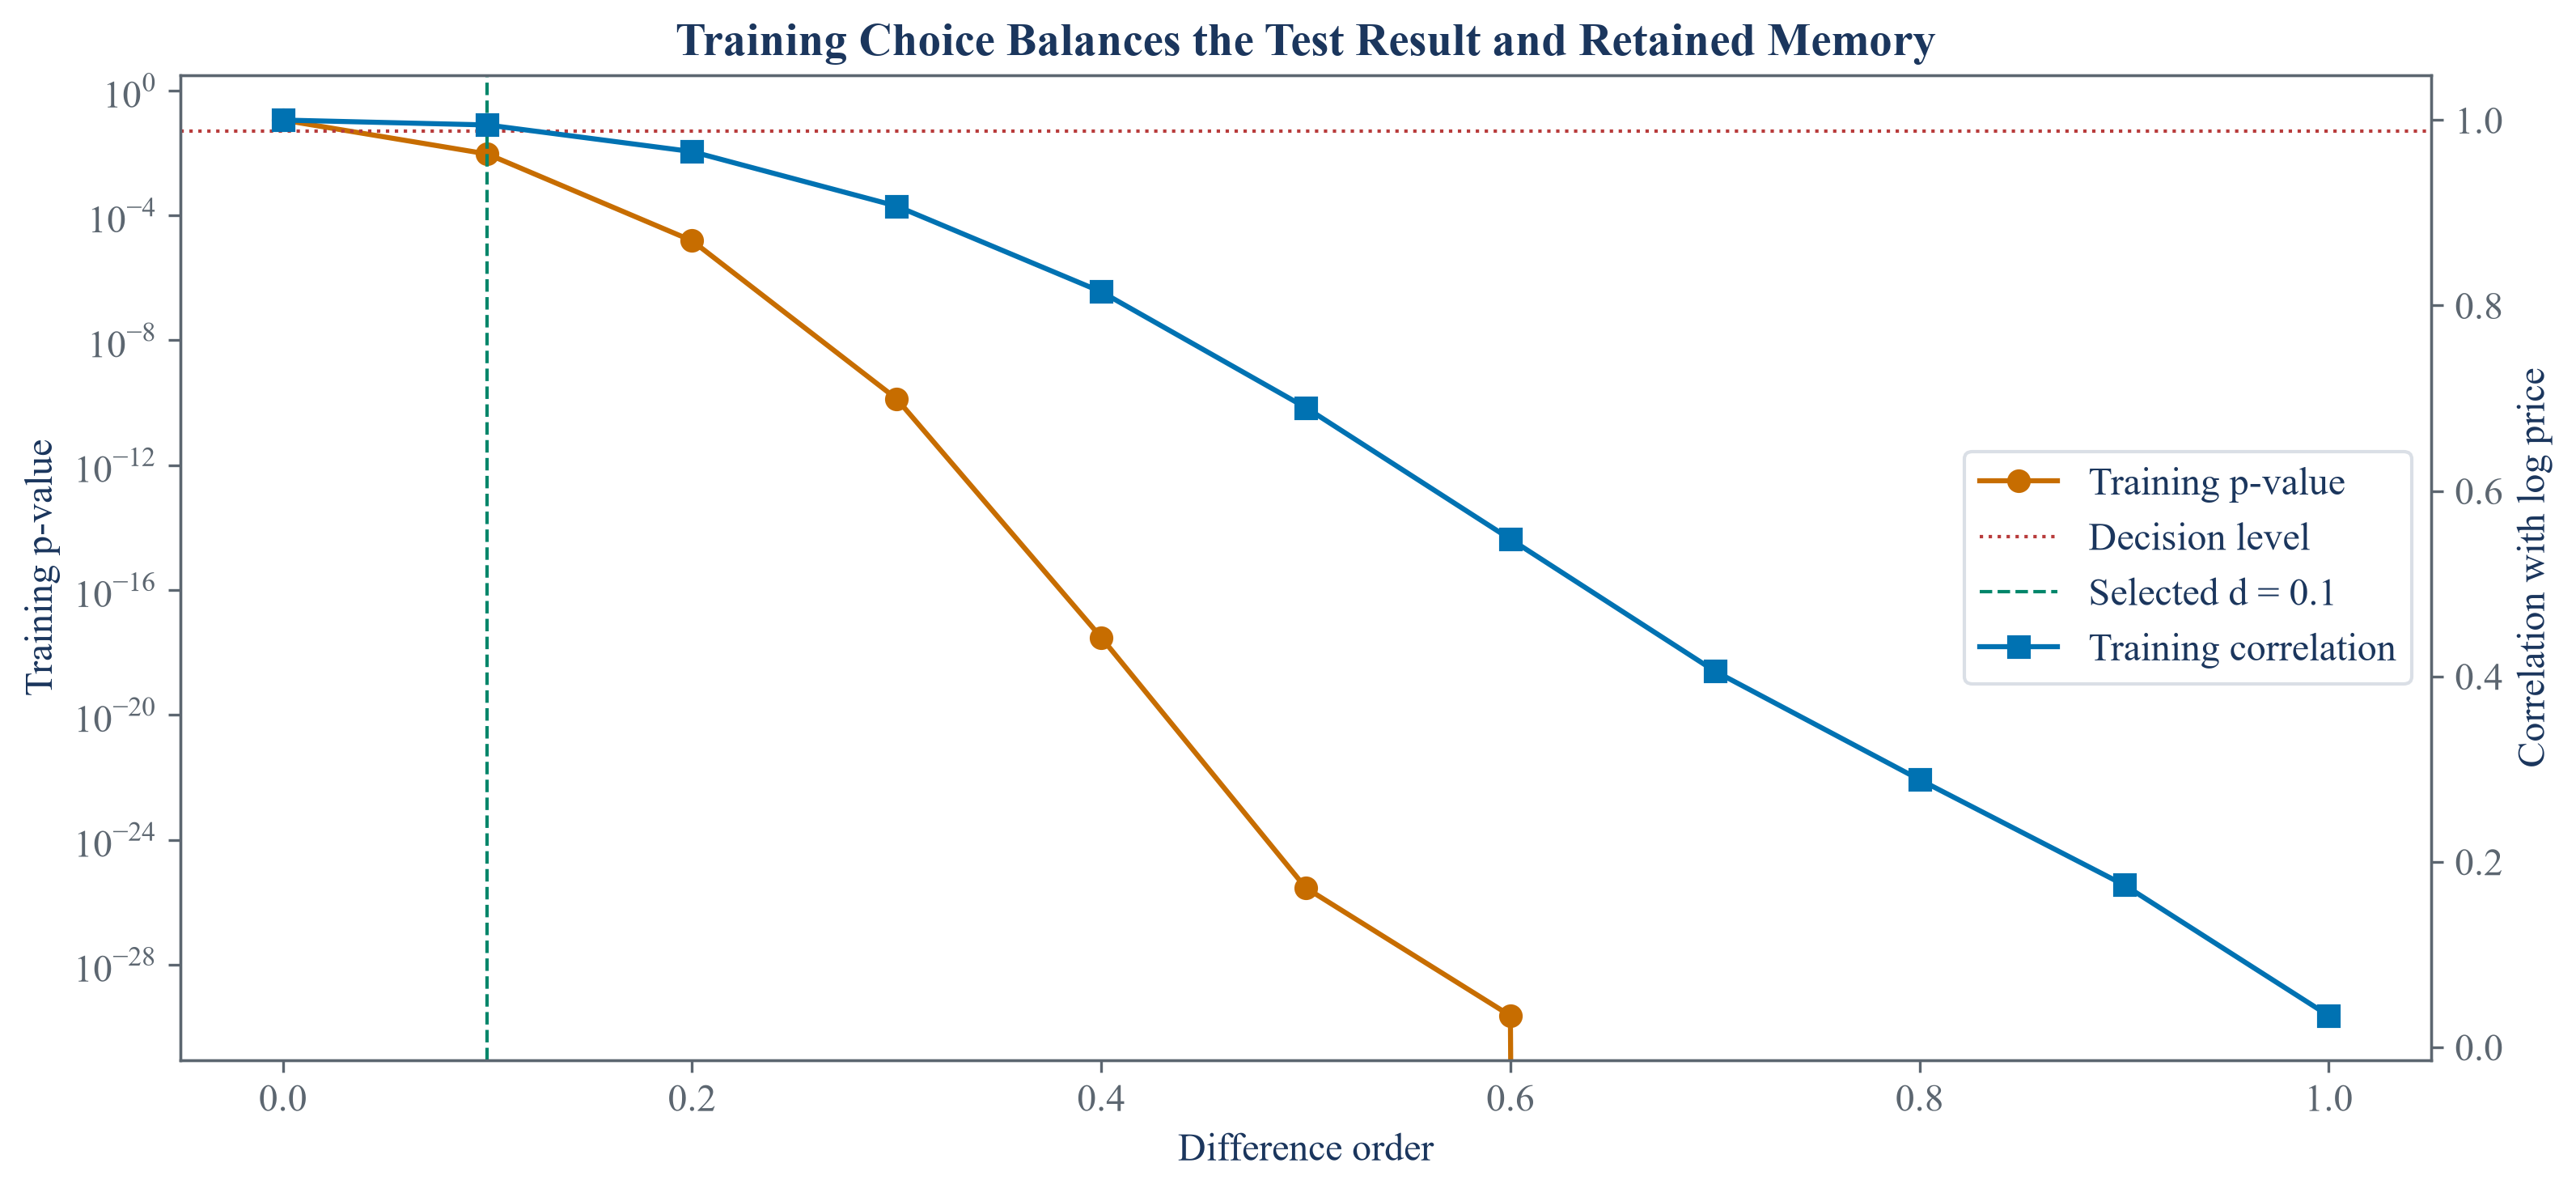

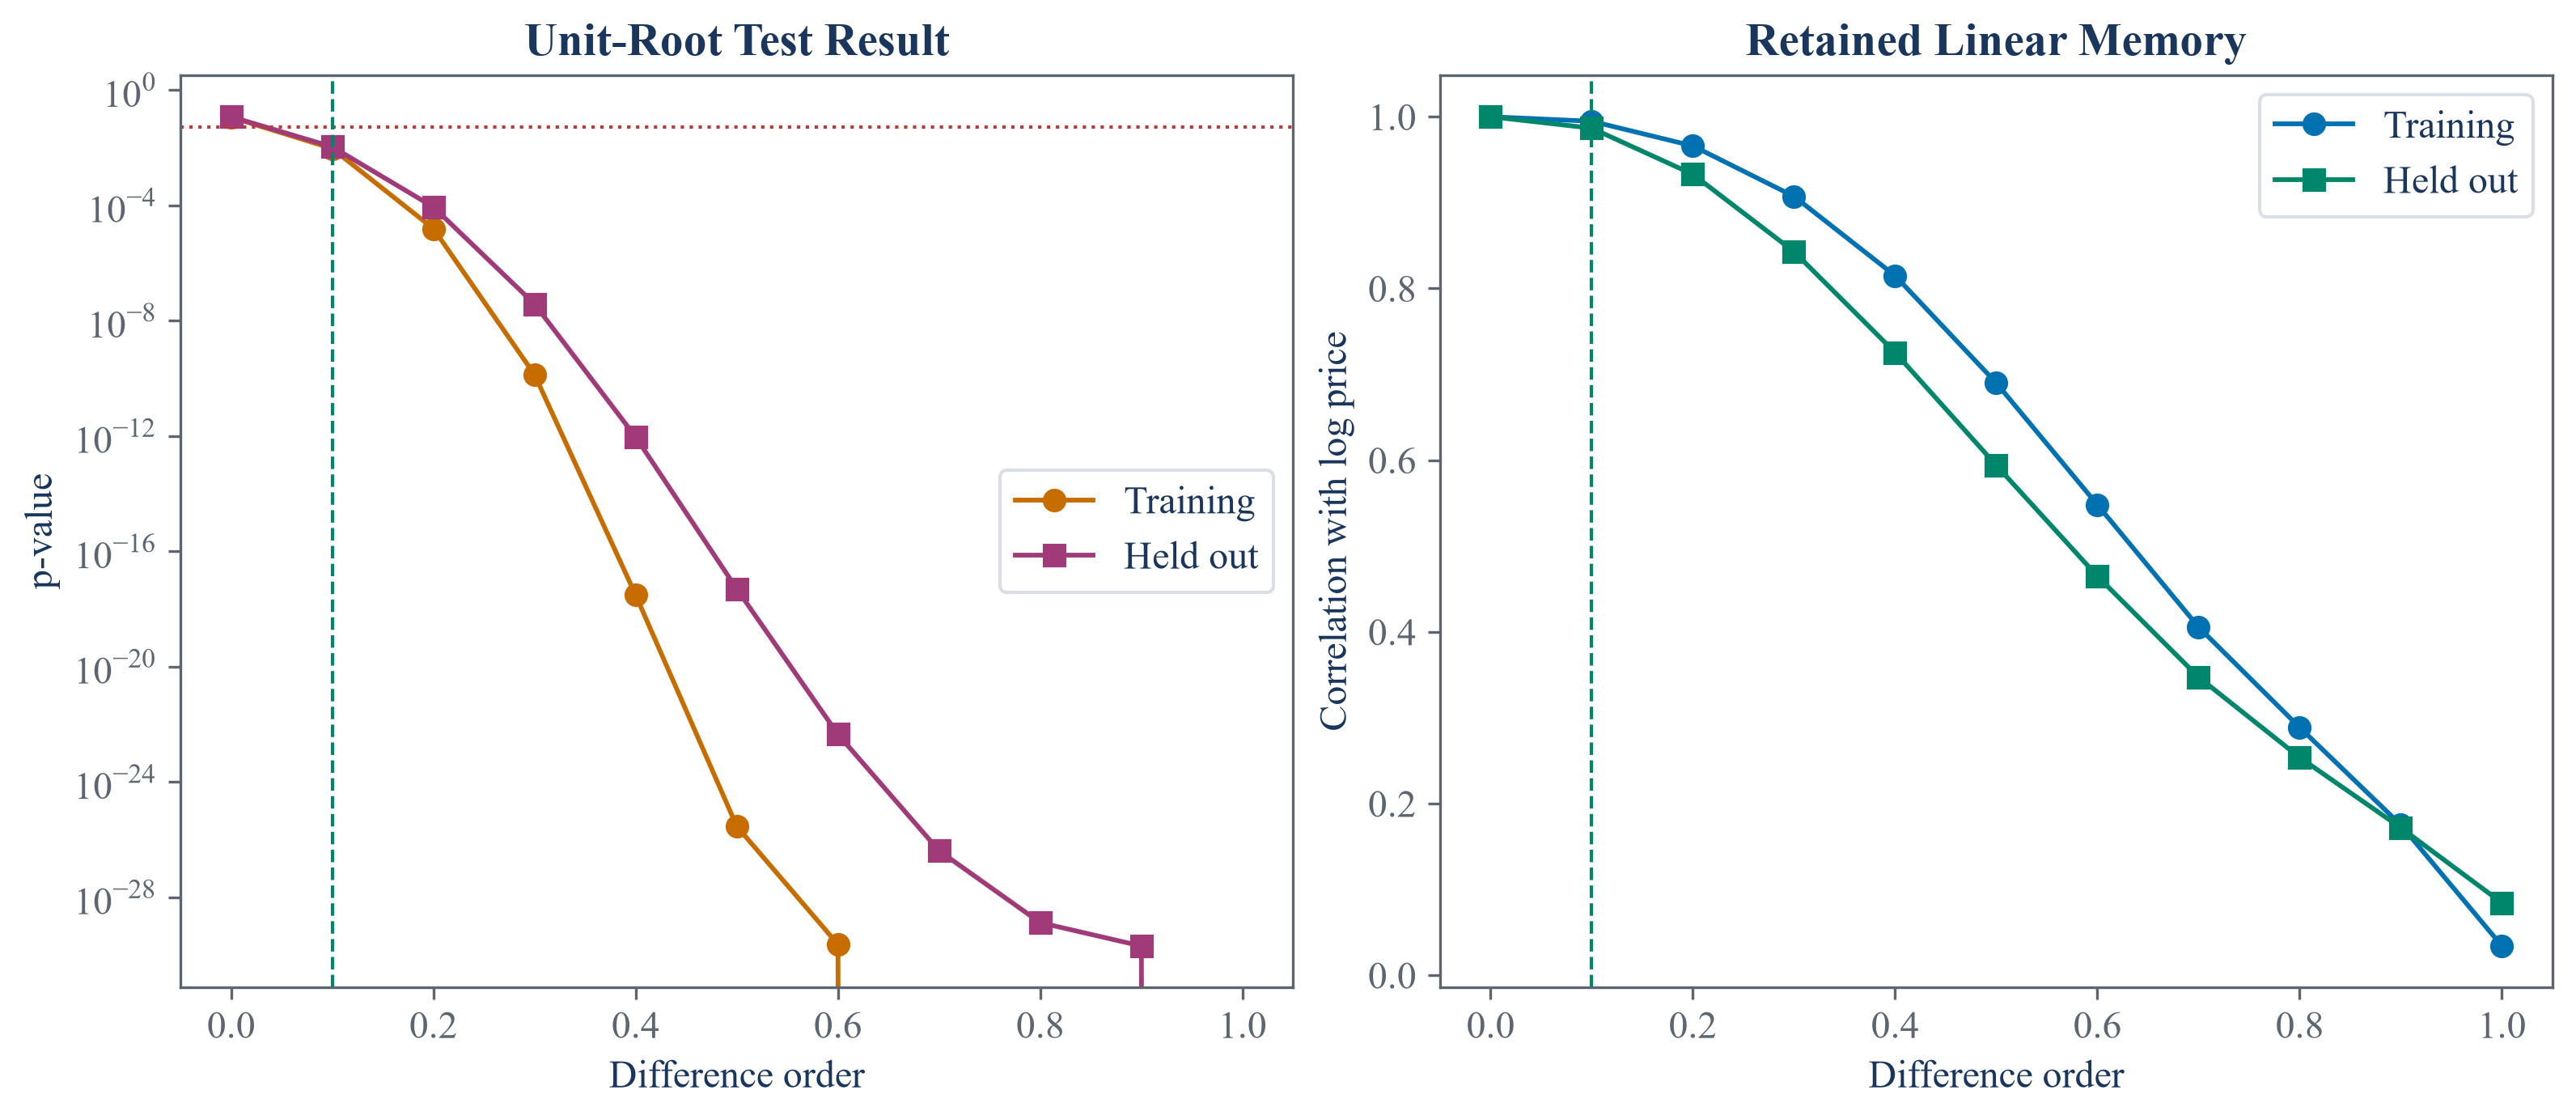

In [3]:
train_selected = train_order_selection.loc[train_order_selection["Order"] == selected_degree].iloc[0]
test_selected = test_order_evaluation.loc[test_order_evaluation["Order"] == selected_degree].iloc[0]
figure, left = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
right = left.twinx()
left.plot(train_order_selection["Order"], train_order_selection["p-value"], marker="o", color=palette["amber"], linewidth=1.5, label="Training p-value")
left.axhline(significance, color=palette["rose"], linewidth=1.0, linestyle=":", label="Decision level")
left.axvline(selected_degree, color=palette["green"], linewidth=1.0, linestyle="--", label=f"Selected d = {selected_degree:.1f}")
right.plot(train_order_selection["Order"], train_order_selection["Correlation with log price"], marker="s", color=palette["cyan"], linewidth=1.5, label="Training correlation")
left.set_yscale("log")
left.set_xlabel("Difference order")
left.set_ylabel("Training p-value")
right.set_ylabel("Correlation with log price")
left.set_title("Training Choice Balances the Test Result and Retained Memory")
handles_left, labels_left = left.get_legend_handles_labels()
handles_right, labels_right = right.get_legend_handles_labels()
left.legend(handles_left + handles_right, labels_left + labels_right, loc="center right")
figure.savefig(FIGURES / "train_order_selection.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "train_order_selection.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "train_order_selection.png")))
plt.close(figure)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
axes[0].plot(train_order_selection["Order"], train_order_selection["p-value"], marker="o", color=palette["amber"], linewidth=1.4, label="Training")
axes[0].plot(test_order_evaluation["Order"], test_order_evaluation["p-value"], marker="s", color=palette["violet"], linewidth=1.4, label="Held out")
axes[0].axhline(significance, color=palette["rose"], linewidth=1.0, linestyle=":")
axes[0].axvline(selected_degree, color=palette["green"], linewidth=1.0, linestyle="--")
axes[0].set_yscale("log")
axes[0].set_title("Unit-Root Test Result")
axes[0].set_xlabel("Difference order")
axes[0].set_ylabel("p-value")
axes[0].legend()
axes[1].plot(train_order_selection["Order"], train_order_selection["Correlation with log price"], marker="o", color=palette["cyan"], linewidth=1.4, label="Training")
axes[1].plot(test_order_evaluation["Order"], test_order_evaluation["Correlation with log price"], marker="s", color=palette["green"], linewidth=1.4, label="Held out")
axes[1].axvline(selected_degree, color=palette["green"], linewidth=1.0, linestyle="--")
axes[1].set_title("Retained Linear Memory")
axes[1].set_xlabel("Difference order")
axes[1].set_ylabel("Correlation with log price")
axes[1].legend()
figure.savefig(FIGURES / "out_of_sample_stability.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "out_of_sample_stability.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "out_of_sample_stability.png")))
plt.close(figure)

## Threshold Sensitivity

Repeating the training rule at several cutoffs shows whether the chosen order depends strongly on how much of the weight tail is retained:

$$
\widehat d(\tau)=\min\{d\in\mathcal D:p_{\mathrm{train}}(d,\tau)<0.05\},
\qquad
\tau\in\{10^{-2},10^{-3},10^{-4},10^{-5}\}.
$$

Here, $\widehat d(\tau)$ is the order chosen at cutoff $\tau$; $\mathcal D$ is the candidate set; $p_{\mathrm{train}}(d,\tau)$ is the training p-value. $10^{-2},10^{-3},10^{-4},10^{-5}$ are the four absolute-weight cutoffs; $0.05$ is the decision level.

## Known-Truth Long-Memory Test

A simulated change series has a known memory order, and cumulative summation adds one unit to the order needed for the price level:

$$
x_t=(1-B)^{-d_0}\varepsilon_t,
\qquad
P_t=\sum_{s=1}^{t}x_s,
\qquad
\tau_0=1+d_0.
$$

Here, $x_t$ is the simulated change at time $t$; $B$ moves a value back one step; $d_0$ is the chosen memory order. $\varepsilon_t$ is independent standard normal noise; $P_t$ is the cumulative level; $s$ indexes changes; $\tau_0$ is the true order for the level.

,Method,Mean selected order,Mean absolute error,Median absolute error,Largest absolute error
0,Minimum order passing the ADF test,0.700000,0.750000,0.700000,1.450000
1,Adaptive fractional difference,0.866711,0.583289,0.597724,0.671745


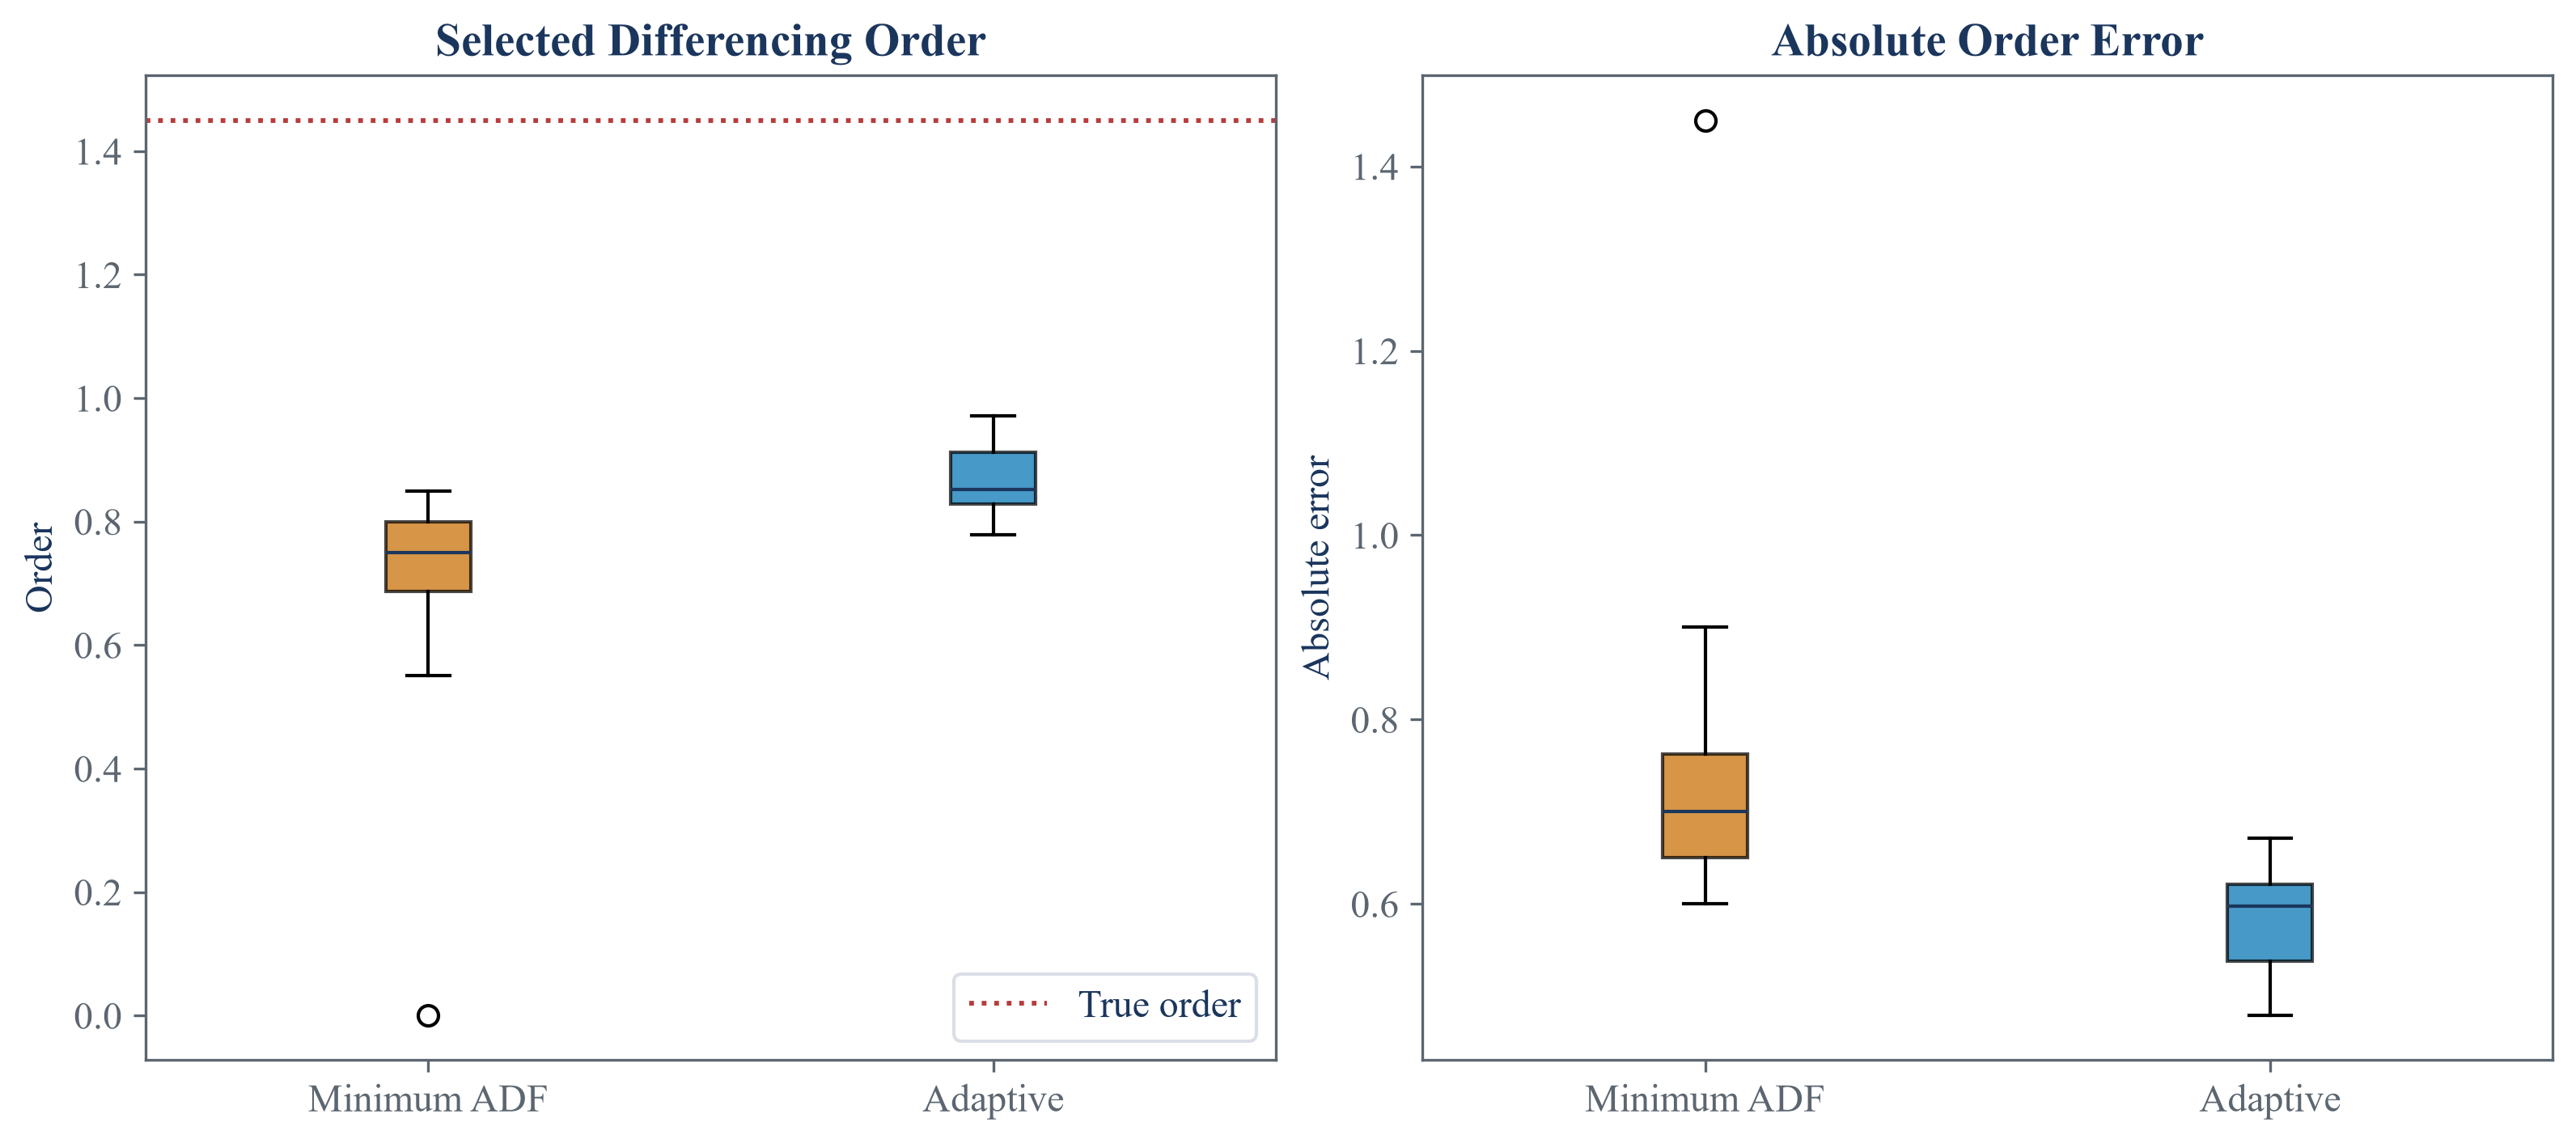

In [4]:
def arfima_increments(memory_order, count, random_generator, burn=512):
    total = count + burn
    innovations = random_generator.standard_normal(total)
    coefficients = np.empty(total)
    coefficients[0] = 1.0
    for lag in range(1, total):
        coefficients[lag] = coefficients[lag - 1] * (lag - 1 + memory_order) / lag
    return fftconvolve(innovations, coefficients)[:total][burn:]

def minimum_stationary_order(price, order_grid, significance_level=0.05, cutoff=1e-4):
    selected = float(order_grid[-1])
    for order in order_grid:
        transformed = fractional_difference_fixed_single(price, float(order), cutoff).dropna()
        if len(transformed) < 20:
            continue
        selected = float(order)
        p_value = float(adfuller(transformed.to_numpy(), maxlag=1, regression="c", autolag=None)[1])
        if p_value < significance_level:
            return selected
    return selected

true_memory_order = 0.45
true_level_order = 1.0 + true_memory_order
simulation_length = 250
order_grid = np.round(np.arange(0.0, 1.2001, 0.05), 2)
order_rows = []
for seed in range(100, 120):
    random_generator = np.random.default_rng(seed)
    simulated_price = pd.Series(np.cumsum(arfima_increments(true_memory_order, simulation_length, random_generator)))
    adaptive_result = adaptive_fractional_difference(simulated_price, delta_grid=list(order_grid))
    baseline_order = minimum_stationary_order(simulated_price, order_grid)
    order_rows.append({"Seed": seed, "True order": true_level_order, "Minimum ADF order": baseline_order, "Adaptive order": adaptive_result["order"], "Minimum ADF absolute error": abs(baseline_order - true_level_order), "Adaptive absolute error": abs(adaptive_result["order"] - true_level_order)})
order_recovery_runs = pd.DataFrame(order_rows)
order_recovery_summary = pd.DataFrame([
    {"Method": "Minimum order passing the ADF test", "Mean selected order": order_recovery_runs["Minimum ADF order"].mean(), "Mean absolute error": order_recovery_runs["Minimum ADF absolute error"].mean(), "Median absolute error": order_recovery_runs["Minimum ADF absolute error"].median(), "Largest absolute error": order_recovery_runs["Minimum ADF absolute error"].max()},
    {"Method": "Adaptive fractional difference", "Mean selected order": order_recovery_runs["Adaptive order"].mean(), "Mean absolute error": order_recovery_runs["Adaptive absolute error"].mean(), "Median absolute error": order_recovery_runs["Adaptive absolute error"].median(), "Largest absolute error": order_recovery_runs["Adaptive absolute error"].max()},
])
save_table(order_recovery_runs, "order_recovery_runs", "Known-truth differencing orders across twenty fixed seeds.", "tab:chapter7-order-recovery-runs", fit=True)
save_table(order_recovery_summary, "order_recovery_summary", "Accuracy of two differencing-order rules on a known-truth long-memory process.", "tab:chapter7-order-recovery-summary", fit=True)
display(order_recovery_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
order_box = axes[0].boxplot([order_recovery_runs["Minimum ADF order"], order_recovery_runs["Adaptive order"]], tick_labels=["Minimum ADF", "Adaptive"], patch_artist=True, medianprops={"color": palette["text"]})
for patch, color in zip(order_box["boxes"], [palette["amber"], palette["cyan"]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.72)
axes[0].axhline(true_level_order, color=palette["rose"], linestyle=":", linewidth=1.4, label="True order")
axes[0].set_title("Selected Differencing Order")
axes[0].set_ylabel("Order")
axes[0].legend()
error_box = axes[1].boxplot([order_recovery_runs["Minimum ADF absolute error"], order_recovery_runs["Adaptive absolute error"]], tick_labels=["Minimum ADF", "Adaptive"], patch_artist=True, medianprops={"color": palette["text"]})
for patch, color in zip(error_box["boxes"], [palette["amber"], palette["cyan"]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.72)
axes[1].set_title("Absolute Order Error")
axes[1].set_ylabel("Absolute error")
figure.savefig(FIGURES / "known_truth_order_recovery.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "known_truth_order_recovery.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "known_truth_order_recovery.png")))
plt.close(figure)

## Tests

In [5]:
selected_full = full_series[selected_degree]
selected_train = train_series[selected_degree]
common_training_index = selected_train.index.intersection(selected_full.index)
selected_test = selected_full.loc[selected_full.index.intersection(test_index)]
sensitivity_choices = dict(zip(threshold_sensitivity["Cutoff"], threshold_sensitivity["Selected order"]))
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(degrees) == 11
assert len(train) == 2083
assert len(test_index) == 893
assert train.index[-1] < test_index[0]
assert selected_degree == 0.1
assert train_selected["p-value"] < significance
assert train_order_selection.loc[train_order_selection["Order"] < selected_degree, "p-value"].ge(significance).all()
assert test_selected["p-value"] < significance
assert test_selected["Correlation with log price"] > 0.98
assert test_order_evaluation.loc[test_order_evaluation["Order"] == 1.0, "Correlation with log price"].iloc[0] < 0.1
assert int(train_selected["Retained weights"]) == 62
assert len(selected_test) == 893
assert np.allclose(selected_train.loc[common_training_index].to_numpy(), selected_full.loc[common_training_index].to_numpy())
assert sensitivity_choices == {0.01: 0.2, 0.001: 0.1, 0.0001: 0.1, 0.00001: 0.4}
assert threshold_sensitivity["Held-out p-value"].lt(significance).all()
assert len(order_recovery_runs) == 20
assert np.isfinite(order_recovery_runs.select_dtypes(include=[float, int]).to_numpy()).all()
assert order_recovery_runs["Adaptive absolute error"].mean() < order_recovery_runs["Minimum ADF absolute error"].mean()
assert np.all(order_recovery_runs["Adaptive order"].between(order_grid.min(), order_grid.max()))
assert (FIGURES / "train_order_selection.pdf").is_file()
assert (FIGURES / "out_of_sample_stability.pdf").is_file()
assert (FIGURES / "known_truth_order_recovery.pdf").is_file()
assert (TABLES / "order_recovery_runs.tex").is_file()
assert (TABLES / "order_recovery_summary.tex").is_file()